In [247]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
#oppgave 1

In [ ]:
# her opner VS filen vi lagde med clinet IDen min som txt på lesemodus som file
# og deretter setter den under variablen cliend_id, og strip() fjerner undøvendige mellomrom  og linjeskift som kan være i filen  
with open('client_id.txt', 'r') as file: 
    client_id = file.read().strip()

In [ ]:
# endpoint er adressen som vi skal hente data fra, i form av URL. Det er en API som har data om været. den sender det ut som JSON formal.
# parmeterene sier hvilken data vi vil hente ut, slikt at sources og iden henviser til værstasjonen i Ås, elements sier at vi vil ha gjennomsnittlig temperatur per dag, og referencetime sier at vi vil ha data for hele 2025.

endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters = {
 'sources': 'SN17850',
 'elements': 'mean(air_temperature P1D)',
 'referencetime': '2025-01-01/2025-12-31',
}

In [ ]:
# det er requests som sender faktisk forespørselen til APIen (nettsiden i koden før/endpoint) med parameterene.
# params er parameterene som vi definerte over, og auth er autentisering som man må ha for å ha tilgang til APIen, som er clinet_id som vi lagde. 
# '' betyr bare at det ikke er noe passord
# print(response.status_code) printer bare statuskoden som viser om forespørselen er vellykket og her skla være 200, og ikke 401 feks som er feilmelding

response = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, "")
)

print(response.status_code)

200


In [285]:
# response.json() gjør om JSOn svaret til data som python kan bruke.
# opprinelig så innholder data alt muligt i den dictionarien, men ved å skrive data['data'], henter vi bare ut det som ligger under nøkkelen 'data'
# df brukes til å lage en tabell av dataen som er under observations, ved å bruke panas biblioteket 

data = response.json()

observations = data['data']

df = pd.DataFrame(observations)


In [ ]:
# temperaturen ligger under observations kolonnen og ikke under sourceId eller referencetime
# derfor gjør df[obervations'].apply() det at python skal gjøre noe med med hver eneste verdi i observations kolonnen.
# lamda x, kaller hver verdi i kolonnen for en x, og x[0]['value'] henter ut den første verdien under nøkkelen 'value' i observations.

df['temperature'] = df['observations'].apply(lambda x: x[0]['value'])


In [ ]:
# i denne linjen gjør vi om referencetime kolonnen til datatime format, så at vi kan plotte grafen med den senere

df['date'] = pd.to_datetime(df['referenceTime'])

df = df[['date','temperature']]

print(df.head())

                       date  temperature
0 2025-01-01 00:00:00+00:00         -5.2
1 2025-01-02 00:00:00+00:00        -11.5
2 2025-01-03 00:00:00+00:00         -8.9
3 2025-01-04 00:00:00+00:00        -15.5
4 2025-01-05 00:00:00+00:00        -12.5


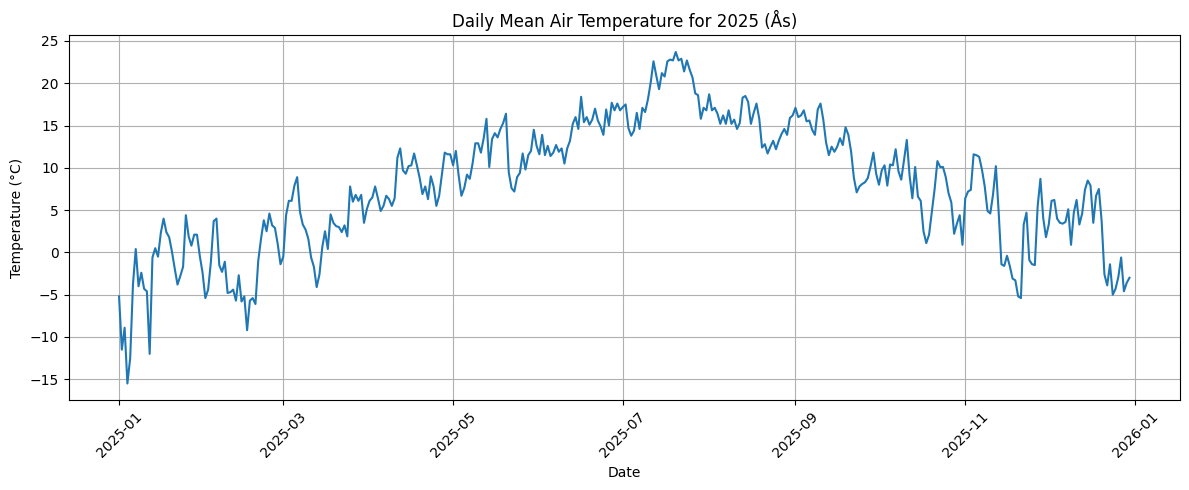

In [255]:
plt.figure(figsize=(12, 5))

plt.plot(df['date'], df['temperature'])

plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.title('Daily Mean Air Temperature for 2025 (Ås)')

plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [256]:
summary = pd.DataFrame({
    'Statistic': ['Mean', 'Median', 'Min', 'Max'],
    'Temperature (°C)': [
        df['temperature'].mean(),
        df['temperature'].median(),
        df['temperature'].min(),
        df['temperature'].max()
    ]
})

print(summary)

  Statistic  Temperature (°C)
0      Mean          7.902747
1    Median          8.400000
2       Min        -15.500000
3       Max         23.700000


In [257]:
#oppgave 2

In [258]:
precipitation_parameters = {
 'sources': 'SN17850',
 'elements': 'sum(precipitation_amount P1D)',
 'referencetime': '2025-01-01/2025-12-31',
}

precipitation_response = requests.get(
    endpoint,
    params=precipitation_parameters,
    auth=(client_id, '')
)

print(precipitation_response.status_code)

200


In [259]:
precipitation_data = precipitation_response.json()

precipitation_observations = precipitation_data['data']

precipitation_df = pd.DataFrame(precipitation_observations)

print(precipitation_df.head())

    sourceId             referenceTime  \
0  SN17850:0  2025-01-01T00:00:00.000Z   
1  SN17850:0  2025-01-02T00:00:00.000Z   
2  SN17850:0  2025-01-03T00:00:00.000Z   
3  SN17850:0  2025-01-04T00:00:00.000Z   
4  SN17850:0  2025-01-05T00:00:00.000Z   

                                        observations  
0  [{'elementId': 'sum(precipitation_amount P1D)'...  
1  [{'elementId': 'sum(precipitation_amount P1D)'...  
2  [{'elementId': 'sum(precipitation_amount P1D)'...  
3  [{'elementId': 'sum(precipitation_amount P1D)'...  
4  [{'elementId': 'sum(precipitation_amount P1D)'...  


In [260]:
precipitation_df['precipitation'] = precipitation_df['observations'].apply(lambda x: x[0]['value'])

In [261]:
precipitation_df['date'] = pd.to_datetime(precipitation_df['referenceTime'])

precipitation_df = precipitation_df[['date', 'precipitation']]

print(precipitation_df.head())

                       date  precipitation
0 2025-01-01 00:00:00+00:00            5.4
1 2025-01-02 00:00:00+00:00            0.0
2 2025-01-03 00:00:00+00:00            0.1
3 2025-01-04 00:00:00+00:00            0.0
4 2025-01-05 00:00:00+00:00            0.5


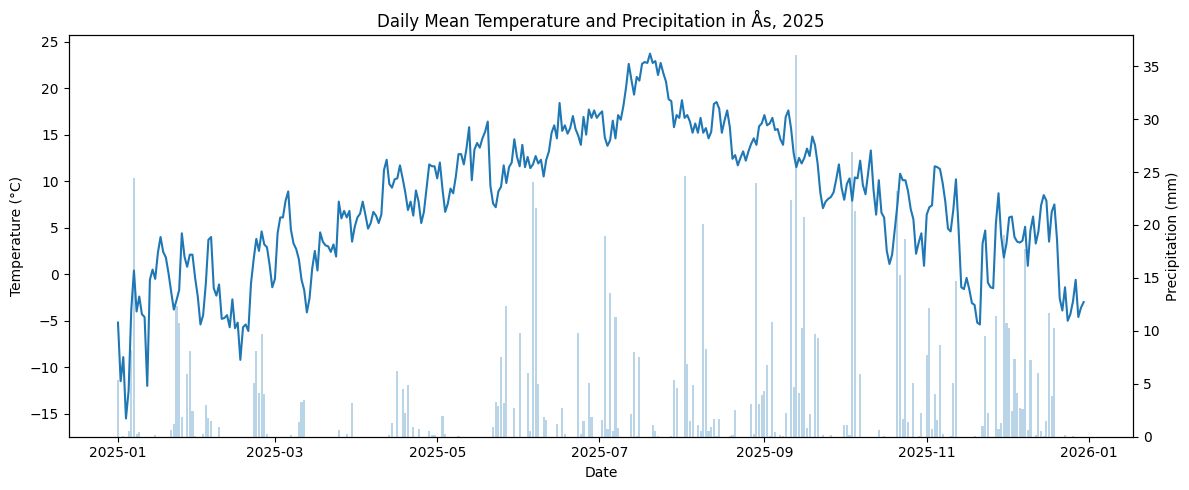

In [262]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Temperature
ax1.plot(
    df["date"],
    df["temperature"],
    label="Temperature"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)")

# Precipitation
ax2 = ax1.twinx()

ax2.bar(
    precipitation_df["date"],
    precipitation_df["precipitation"],
    alpha=0.3,
    label="Precipitation"
)

ax2.set_ylabel("Precipitation (mm)")

plt.title("Daily Mean Temperature and Precipitation in Ås, 2025")
plt.xticks(rotation=45)

fig.tight_layout()
plt.show()

#jeg tenker det er bedre  ha en vanlig linje graf for temperaturer fordi at den viser hvordan temperaturen endrer seg over tid
# for regn, tenker jeg derimot at en stolpediagram ser bedre ut fordi den viser mengden regn på en dag (ved at regn fra gårsdagen og imorgen ikke er relatert til dagen i dag)

In [263]:
# oppgave 3

In [264]:
historical_parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '1925-01-01/1925-12-31',
}

historical_response = requests.get(
    endpoint,
    params=historical_parameters,
    auth=(client_id, '')
)

print(historical_response.status_code)

200


In [265]:
historical_data = historical_response.json()

historical_observations = historical_data['data']

historical_df = pd.DataFrame(historical_observations)

print(historical_df.head())

    sourceId             referenceTime  \
0  SN17850:0  1925-01-01T00:00:00.000Z   
1  SN17850:0  1925-01-02T00:00:00.000Z   
2  SN17850:0  1925-01-03T00:00:00.000Z   
3  SN17850:0  1925-01-04T00:00:00.000Z   
4  SN17850:0  1925-01-05T00:00:00.000Z   

                                        observations  
0  [{'elementId': 'mean(air_temperature P1D)', 'v...  
1  [{'elementId': 'mean(air_temperature P1D)', 'v...  
2  [{'elementId': 'mean(air_temperature P1D)', 'v...  
3  [{'elementId': 'mean(air_temperature P1D)', 'v...  
4  [{'elementId': 'mean(air_temperature P1D)', 'v...  


In [266]:
historical_df['temperature'] = historical_df['observations'].apply(lambda x: x[0]['value'])

In [267]:
historical_df['date'] = pd.to_datetime(historical_df['referenceTime'])

historical_df = historical_df[['date', 'temperature']]

print(historical_df.head())

                       date  temperature
0 1925-01-01 00:00:00+00:00          1.3
1 1925-01-02 00:00:00+00:00          4.1
2 1925-01-03 00:00:00+00:00          2.1
3 1925-01-04 00:00:00+00:00          0.1
4 1925-01-05 00:00:00+00:00         -2.2


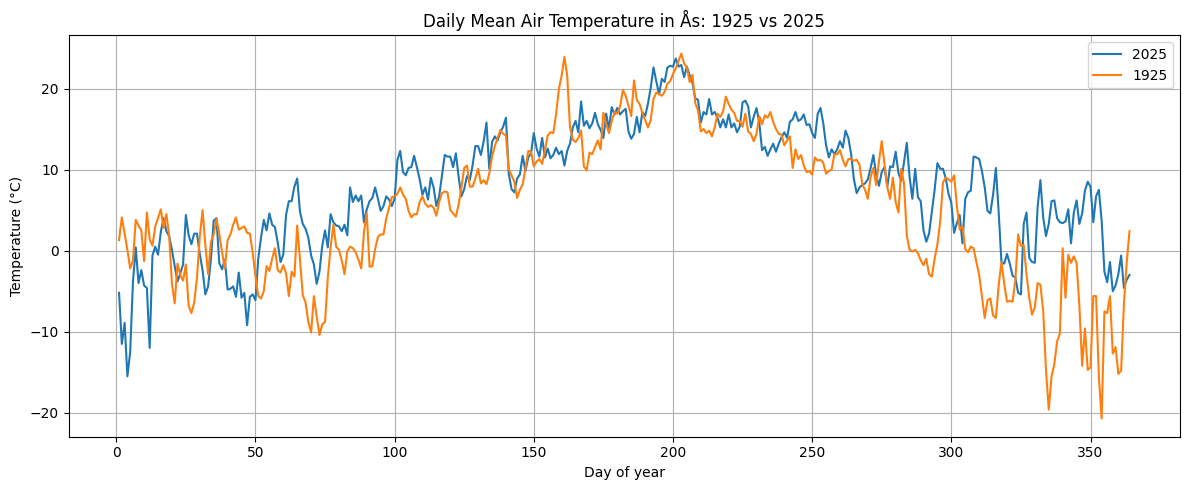

In [268]:
df["day_of_year"] = df["date"].dt.dayofyear
historical_df["day_of_year"] = historical_df["date"].dt.dayofyear

plt.figure(figsize=(12, 5))

plt.plot(
    df["day_of_year"],
    df["temperature"],
    label="2025"
)

plt.plot(
    historical_df["day_of_year"],
    historical_df["temperature"],
    label="1925"
)

plt.xlabel("Day of year")
plt.ylabel("Temperature (°C)")
plt.title("Daily Mean Air Temperature in Ås: 1925 vs 2025")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [269]:
historical_summary = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", "Maximum"],
    "1925 (°C)": [
        historical_df["temperature"].mean(),
        historical_df["temperature"].median(),
        historical_df["temperature"].min(),
        historical_df["temperature"].max()
    ],
    "2025 (°C)": [
        df["temperature"].mean(),
        df["temperature"].median(),
        df["temperature"].min(),
        df["temperature"].max()
    ]
})

print(historical_summary)

  Statistic  1925 (°C)  2025 (°C)
0      Mean    5.31044   7.902747
1    Median    5.30000   8.400000
2   Minimum  -20.70000 -15.500000
3   Maximum   24.30000  23.700000


In [270]:
#oppgave 4

In [ ]:
import yaml


def count_heatwaves(station_id, station_name, year):

    parameters = {
        "sources": station_id,
        "elements": "max(air_temperature P1D)",
        "referencetime": f"{year}-01-01/{year}-12-31"
    }

    response = requests.get(
        endpoint,
        params=parameters,
        auth=(client_id, "")
    )

    print("Status code:", response.status_code)

    data = response.json()
    observations = data["data"]

    df_heat = pd.DataFrame(observations)

    # Hent temperatur
    df_heat["temperature"] = df_heat["observations"].apply(
        lambda x: x[0]["value"]
    )

    # Hent dato
    df_heat["date"] = pd.to_datetime(
        df_heat["referenceTime"]
    )

    df_heat = df_heat[["date", "temperature"]]

    # her finner vi ut heatwaves
    heatwaves = []
    current_heatwave = []

    for i in range(len(df_heat)):

        temperature = df_heat.loc[i, "temperature"]
        date = df_heat.loc[i, "date"]

        if temperature >= 27:
            current_heatwave.append(
                date.strftime("%Y-%m-%d")
            )

        else:
            if len(current_heatwave) >= 5:
                heatwaves.append(current_heatwave)

            current_heatwave = []

    # Sjekk hvis året slutter midt i en heatwave
    if len(current_heatwave) >= 5:
        heatwaves.append(current_heatwave)

    # her lager vi en liste med alle datoene
    dates = []

    for heatwave in heatwaves:
        dates.extend(heatwave)

    # summary
    summary = {
        "dates": dates,
        "station_id": station_id,
        "station_name": station_name,
        "year": year
    }

    # Skriv til YAML
    with open("heatwave_summary.yml", "w") as file:
        yaml.dump(
            summary,
            file,
            sort_keys=False,
            allow_unicode=True
        )

    return len(heatwaves)

number_of_heatwaves = count_heatwaves(
    "SN17850",
    "Ås",
    2025
)

print("Number of heatwaves:", number_of_heatwaves)

Status code: 200
Number of heatwaves: 1


In [272]:
#oppgave 5

In [273]:
def moving_average(temperatures, window=7):
    averages = []

    for i in range(len(temperatures)):
        if i < window - 1:
            averages.append(None)
        else:
            values = temperatures[i-window+1:i+1]
            average = sum(values) / window
            averages.append(average)

    return averages

In [274]:
df["moving_average"] = moving_average(
    df["temperature"].tolist()
)

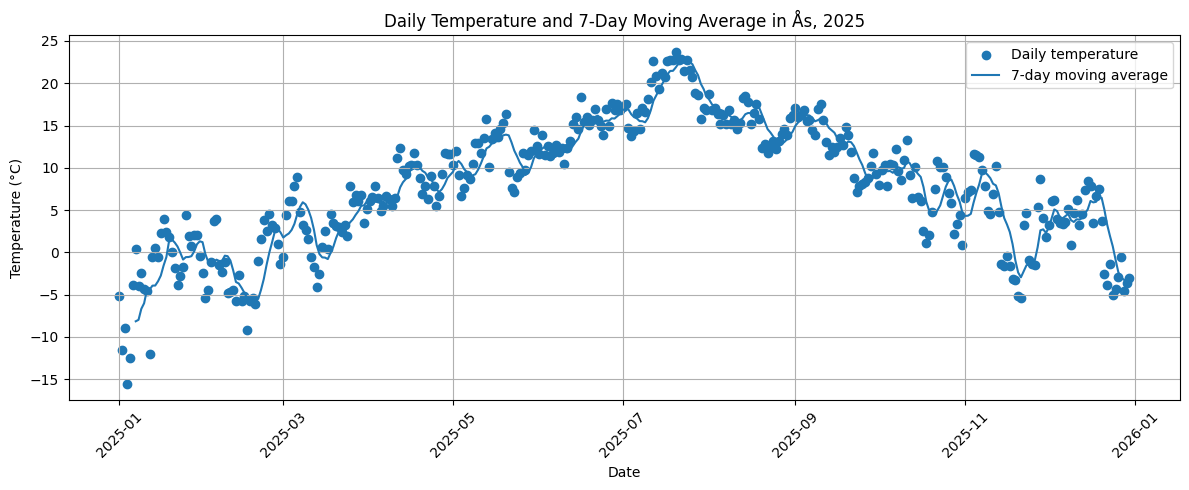

In [275]:
plt.figure(figsize=(12, 5))

# Daglige temperaturer som punkter
plt.scatter(
    df["date"],
    df["temperature"],
    label="Daily temperature"
)

# 7-dagers moving average som linje
plt.plot(
    df["date"],
    df["moving_average"],
    label="7-day moving average"
)

plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("Daily Temperature and 7-Day Moving Average in Ås, 2025")

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()